# Modelado y cierre de Fase 3

## 1. Metodología y evidencia

Se conservan la división temporal del proyecto, las etiquetas de frontera eliminadas y el criterio de filas comunes. El candidato fue fijado por su MAE de validación. Las búsquedas originales permanecen en los notebooks por familia y sus ramas, identificadas en el informe de comparación. Este notebook solo consulta CSV, JSON e imágenes archivados: no carga el dataset procesado, no ajusta modelos y no ejecuta test. Repetir sus celdas no consume otra evaluación.

In [1]:
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from auxiliar_functions import tabla_simple

SALIDA = RAIZ / "results/lasso_final"
def leer(nombre):
    return json.loads((SALIDA / nombre).read_text(encoding="utf-8"))
def mostrar(numero, titulo, tabla, precision=6):
    print(f"Tabla {numero}. {titulo}")
    display(tabla_simple(tabla, precision=precision))
meta = leer("entrenamiento.json")
resultado = leer("evaluacion_test.json")
log = pd.read_csv(RAIZ / "results/experiment_logs.csv")
validacion = log.loc[log.tramo.eq("validacion")].sort_values("mae", kind="stable")
mostrar(1, "Registro de validación: todas las ejecuciones históricas", validacion[
    ["modelo", "fecha_hora", "filas", "mae", "rmse", "r2", "hiperparametros", "notas"]])

Tabla 1. Registro de validación: todas las ejecuciones históricas


,modelo,fecha_hora,filas,mae,rmse,r2,hiperparametros,notas
271,lasso,2026-11-14T16:38:40,171,2215.796375,2835.803834,0.467609,"{""alpha"": 75.0, ""max_iter"": 20000, ""random_state"": 42}",mejor configuración por MAE cruzado; pipeline A; configuración 6
314,lasso,2026-11-14T17:35:09,171,2215.796375,2835.803834,0.467609,"{""alpha"": 75.0, ""max_iter"": 20000, ""random_state"": 42}",Optuna 5.0.0; TPE; mejor ensayo por MAE cruzado 2
96,xgboost,2026-11-14T18:35:43,171,2221.760634,2844.307419,0.464411,"{""colsample_bytree"": 0.8086142929785466, ""eval_metric"": ""mae"", ""gamma"": 0, ""learning_rate"": 0.0020702351473759497, ""max_depth"": 3, ""min_child_weight"": 4.49480789319248, ""n_estimators"": 1908, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 1, ""subsample"": 0.9516935603337213, ""tree_method"": ""hist""}",15 variables con es_fin_de_anio; validacion independiente; Optuna xgboost-temporal-15-features-v1; trial 56; ajuste 830 filas; sin nueva optimizacion
260,ridge,2026-11-14T16:38:35,171,2225.443177,2863.228861,0.457262,"{""alpha"": 30.0, ""random_state"": 42}",mejor configuración por MAE cruzado; pipeline A; configuración 6
303,ridge,2026-11-14T17:35:06,171,2225.443177,2863.228861,0.457262,"{""alpha"": 30.0, ""random_state"": 42}",Optuna 5.0.0; TPE; mejor ensayo por MAE cruzado 2
142,xgboost,2026-11-14T19:26:21,171,2229.224629,2853.130568,0.461083,"{""colsample_bytree"": 0.89176387518403, ""eval_metric"": ""mae"", ""gamma"": 0, ""learning_rate"": 0.0020702351473759497, ""max_depth"": 3, ""min_child_weight"": 4.632253473557002, ""n_estimators"": 1994, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 1, ""subsample"": 0.9642293818510409, ""tree_method"": ""hist""}",15 features; estudio refinado xgboost-temporal-15-features-refinado-v1; trial 49; ajuste 830 filas; eval_set train y validacion independiente 171; sin early stopping ni reajuste
357,lasso,2026-11-14T17:55:36,171,2265.620734,2901.502186,0.442655,"{""alpha"": 75.0, ""max_iter"": 20000, ""random_state"": 42}",15 variables con es_fin_de_anio; mejor configuración por MAE cruzado; pipeline A; configuración 6
400,lasso,2026-11-14T17:58:05,171,2265.620734,2901.502186,0.442655,"{""alpha"": 75.0, ""max_iter"": 20000, ""random_state"": 42}",15 variables con es_fin_de_anio; Optuna 5.0.0; TPE; mejor ensayo por MAE cruzado 2
228,lightgbm,2026-11-14T20:04:25,171,2276.735434,2873.135674,0.453499,"{""colsample_bytree"": 0.8638540491377883, ""learning_rate"": 0.036985470389312915, ""max_depth"": 3, ""min_child_samples"": 31, ""n_estimators"": 200, ""n_jobs"": 1, ""num_leaves"": 8, ""random_state"": 42, ""reg_alpha"": 0.4172446705183493, ""reg_lambda"": 2.5151783649755584, ""subsample"": 0.7870286296445328, ""subsample_freq"": 1, ""verbosity"": -1}",Optuna lightgbm-temporal-v2; ganador trial=99; validacion independiente; solo ajuste entrenamiento
346,ridge,2026-11-14T17:55:32,171,2284.201258,2936.328466,0.429195,"{""alpha"": 30.0, ""random_state"": 42}",15 variables con es_fin_de_anio; mejor configuración por MAE cruzado; pipeline A; configuración 6


## 2. Selección fijada por validación

Se presenta la mejor configuración por familia, incluidos los baselines. El registro mantiene por separado las búsquedas iniciales y Optuna aunque repitan resultados. Lasso usa la lista histórica de catorce entradas; no incorpora el indicador agregado posteriormente al contrato de quince. Los resultados de selección de variables de Fase 2 se documentan como antecedentes en comparacion_modelos_final.md y no se reabre la selección de Fase 3.

In [2]:
mostrar(2, "Mejor configuración por familia en validación", validacion.drop_duplicates("modelo")[
    ["modelo", "filas", "mae", "rmse", "r2", "hiperparametros"]])
mostrar(3, "Configuración ganadora y evidencia original", pd.DataFrame([{
    "Modelo": meta["modelo"], "Pipeline": meta["pipeline"], **meta["hiperparametros"],
    **{f"Validación original {k}": v for k,v in meta["metricas_validacion_original"].items()}}]))
mostrar(4, "Entradas ganadoras en su orden", pd.DataFrame({"Variable": meta["columnas"]}))

Tabla 2. Mejor configuración por familia en validación


,modelo,filas,mae,rmse,r2,hiperparametros
271,lasso,171,2215.796375,2835.803834,0.467609,"{""alpha"": 75.0, ""max_iter"": 20000, ""random_state"": 42}"
96,xgboost,171,2221.760634,2844.307419,0.464411,"{""colsample_bytree"": 0.8086142929785466, ""eval_metric"": ""mae"", ""gamma"": 0, ""learning_rate"": 0.0020702351473759497, ""max_depth"": 3, ""min_child_weight"": 4.49480789319248, ""n_estimators"": 1908, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 1, ""subsample"": 0.9516935603337213, ""tree_method"": ""hist""}"
260,ridge,171,2225.443177,2863.228861,0.457262,"{""alpha"": 30.0, ""random_state"": 42}"
228,lightgbm,171,2276.735434,2873.135674,0.453499,"{""colsample_bytree"": 0.8638540491377883, ""learning_rate"": 0.036985470389312915, ""max_depth"": 3, ""min_child_samples"": 31, ""n_estimators"": 200, ""n_jobs"": 1, ""num_leaves"": 8, ""random_state"": 42, ""reg_alpha"": 0.4172446705183493, ""reg_lambda"": 2.5151783649755584, ""subsample"": 0.7870286296445328, ""subsample_freq"": 1, ""verbosity"": -1}"
335,random_forest,171,2284.521083,2954.749666,0.422011,"{""max_depth"": 10, ""max_features"": 0.5, ""min_samples_leaf"": 12, ""n_estimators"": 200, ""n_jobs"": 1, ""random_state"": 42}"
883,gradient_boosting,171,2316.309953,2948.038902,0.424633,"{""learning_rate"": 0.01592324888670594, ""loss"": ""absolute_error"", ""max_depth"": 2, ""max_features"": 0.8, ""min_samples_leaf"": 4, ""n_estimators"": 550, ""n_iter_no_change"": null, ""random_state"": 42, ""subsample"": 0.8}"
3,media_movil,171,2497.653578,3368.075201,0.248997,"{""minimo_dias"": 4, ""ventana"": 7}"
2,persistencia,171,2668.327485,3319.433584,0.270532,{}


Tabla 3. Configuración ganadora y evidencia original


,Modelo,Pipeline,alpha,max_iter,random_state,Validación original mae,Validación original rmse,Validación original r2
0,Lasso,A,75.000000,20000,42,2215.796375,2835.803834,0.467609


Tabla 4. Entradas ganadoras en su orden


,Variable
0,Frio (Kw)
1,Frio (Kw) x frio_hace_2_dias
2,frio_media_7_dias
3,Sala Maq (Kw)
4,Frio (Kw) x Consolidado Agua | Agua Planta (Hl)
5,Servicios (Kw)
6,Frio (Kw) x Totalizadores Energia | KW Trafo 9
7,dia_anio_coseno
8,frio_hace_2_dias x Consolidado Agua | Agua Planta (Hl)
9,dia_anio_coseno x Consolidado Agua | Agua Planta (Hl)


## 3. Reentrenamiento y congelamiento

El script train_model.py reconstruye pipeline A y reajusta mediana, escalado estándar y Lasso con entrenamiento más validación. Verifica dos ajustes deterministas y la carga joblib antes de test. El commit del código entrenado se conserva en el registry y el artefacto; el tag identifica el commit posterior que contiene los resultados. Las métricas de ajuste son dentro de muestra y no sustituyen la validación histórica.

In [3]:
mostrar(5, "Reentrenamiento final y verificaciones previas a test", pd.DataFrame([{
    "Versión": meta["version"], "Train": meta["filas_por_tramo"]["entrenamiento"],
    "Validation": meta["filas_por_tramo"]["validacion"], "Total": meta["filas_train_validation"],
    "Commit de entrenamiento": meta["commit"], "Python": meta["python"], **meta["reproducibilidad"]}]))
mostrar(6, "Métricas de ajuste dentro de muestra, no validación", pd.DataFrame([meta["metricas_ajuste_no_validacion"]]))

Tabla 5. Reentrenamiento final y verificaciones previas a test


,Versión,Train,Validation,Total,Commit de entrenamiento,Python,dos_ajustes_coinciden,joblib_reproduce_predicciones,medianas_solo_train_validation
0,1.0.0,830,176,1006,6afd3c0bcb02bc98c0348e19cbe690d5c747f97b,3.12.14,True,True,True


Tabla 6. Métricas de ajuste dentro de muestra, no validación


,mae,rmse,r2
0,2722.696701,3532.641094,0.795671


## 4. Evaluación única sobre test local

La ejecución explícita crea un marcador exclusivo antes de leer las observaciones de prueba. Modelo y baselines comparten el soporte con objetivo y ambas referencias disponibles. La media móvil sigue la definición del proyecto: siete bloques hasta D, con mínimo de cuatro valores válidos. Las consultas posteriores verifican los archivos guardados y no predicen nuevamente. El umbral eliminatorio de la consigna corresponde al test oculto, no al local.

Tabla 7. Test local: modelo y baselines sobre las mismas observaciones


,mae,rmse,r2
Modelo,,,
lasso,2886.038956,3737.100018,0.574969
persistencia,3291.982955,4263.763539,0.446729
media_movil,3063.784497,3979.543389,0.518032


Tabla 8. Soporte de la evaluación única


,Test etiquetado,Filas evaluadas,Índices excluidos,Predicciones de test
0,178,176,"[1070, 1123]",1


Tabla 9. Diferencia de MAE y mejora porcentual frente a baselines


,diferencia_mae,mejora_porcentual
persistencia,405.943999,12.331291
media_movil,177.745541,5.801503


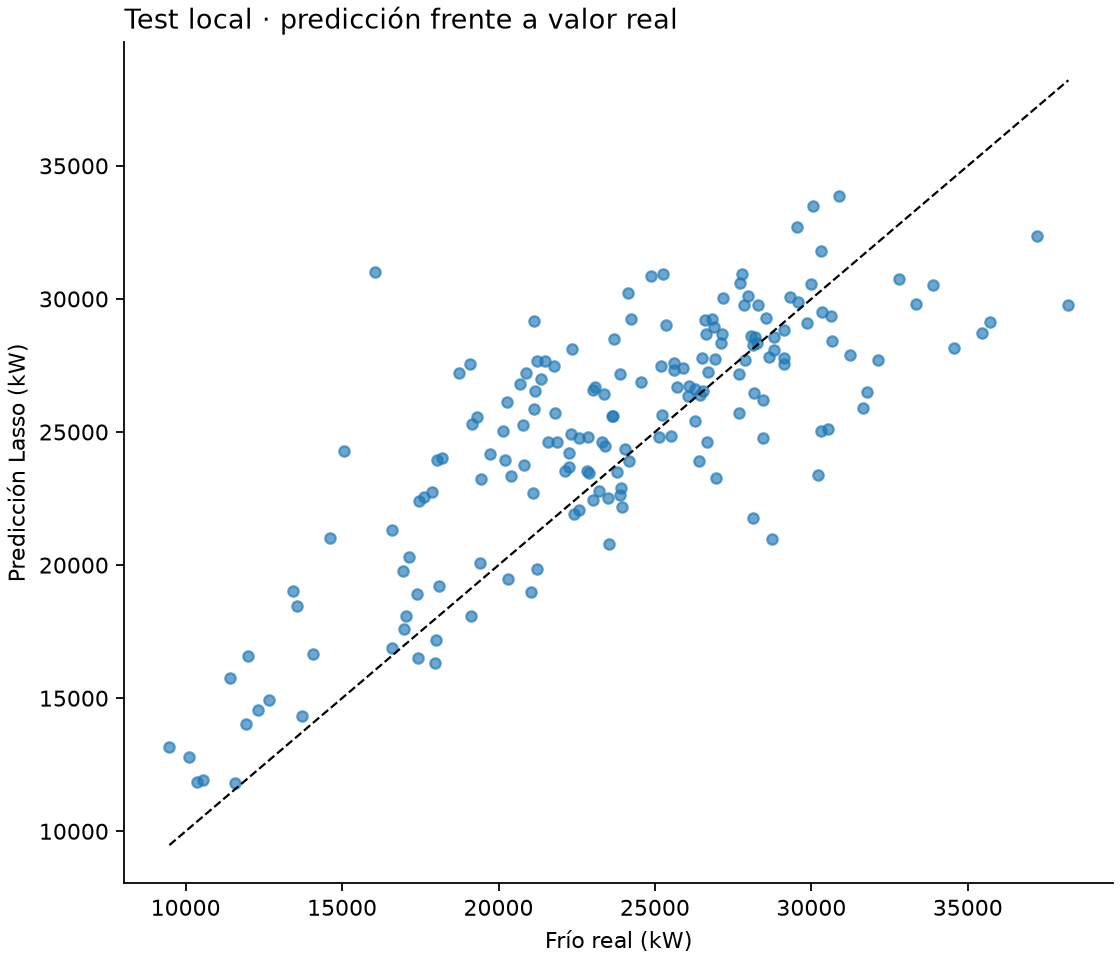

In [4]:
comparacion = pd.DataFrame(resultado["metricas"]).T.rename_axis("Modelo")
mostrar(7, "Test local: modelo y baselines sobre las mismas observaciones", comparacion)
mostrar(8, "Soporte de la evaluación única", pd.DataFrame([{
    "Test etiquetado": resultado["filas_test_etiquetadas"], "Filas evaluadas": resultado["filas_evaluadas"],
    "Índices excluidos": str(resultado["indices_excluidos"]), "Predicciones de test": resultado["evaluaciones_predict_test"]}]))
mostrar(9, "Diferencia de MAE y mejora porcentual frente a baselines", pd.DataFrame(resultado["comparaciones"]).T)
display(Image(filename=str(SALIDA / "prediccion_vs_real.png")))

## 5. Residuos, sesgos y errores grandes

Se define residuo como real menos predicho. Un valor positivo indica subestimación; uno negativo, sobreestimación. Se muestran distribución, dispersión y evolución temporal, junto con los mayores errores y el sesgo por cuartil del consumo real. Este diagnóstico es descriptivo: no habilita descartar observaciones ni ajustar el modelo después de test.

Tabla 10. Resumen de residuos de test local


,residuo_medio,residuo_mediano,desvio_residuo,error_absoluto_maximo,p90_error_absoluto,coeficientes_no_nulos,residuos_positivos,residuos_negativos
0,-1274.472771,-1334.093688,3523.089459,14970.715398,6133.789650,6,58,118


Tabla 11. Residuos por nivel de consumo real


,real,filas,real_medio,residuo_medio,mae
0,"(9480.999, 20306.25]",44,16065.477273,-3626.689836,3825.980174
1,"(20306.25, 23879.5]",44,22209.886364,-2379.168202,2902.048127
2,"(23879.5, 27897.5]",44,26023.954545,-1181.688777,1899.529854
3,"(27897.5, 38215.0]",44,30530.681818,2089.655733,2916.597669


Tabla 12. Observaciones con mayor error absoluto


,indice_csv,DIA,real,predicho,persistencia,media_movil,residuo,error_absoluto
0,1102,2023-08-02,16048.000000,31018.715398,30892.000000,30359.428571,-14970.715398,14970.715398
1,1063,2023-06-24,15073.000000,24301.864158,23887.000000,24282.142857,-9228.864158,9228.864158
2,1012,2023-05-03,18731.000000,27229.613744,28453.000000,22642.000000,-8498.613744,8498.613744
3,1122,2023-08-22,19075.000000,27568.667471,25259.000000,27594.571429,-8493.667471,8493.667471
4,1100,2023-07-31,38215.000000,29784.189329,29321.000000,27535.000000,8430.810671,8430.810671
5,1142,2023-09-14,21128.000000,29170.302239,32127.000000,27146.714286,-8042.302239,8042.302239
6,1138,2023-09-10,28749.000000,20997.246387,19143.000000,23518.857143,7751.753613,7751.753613
7,1103,2023-08-03,30221.000000,23396.856788,16048.000000,28384.428571,6824.143212,6824.143212
8,1128,2023-08-29,35467.000000,28725.634558,31666.000000,23721.333333,6741.365442,6741.365442
9,1087,2023-07-18,35719.000000,29122.766576,26599.000000,27804.285714,6596.233424,6596.233424


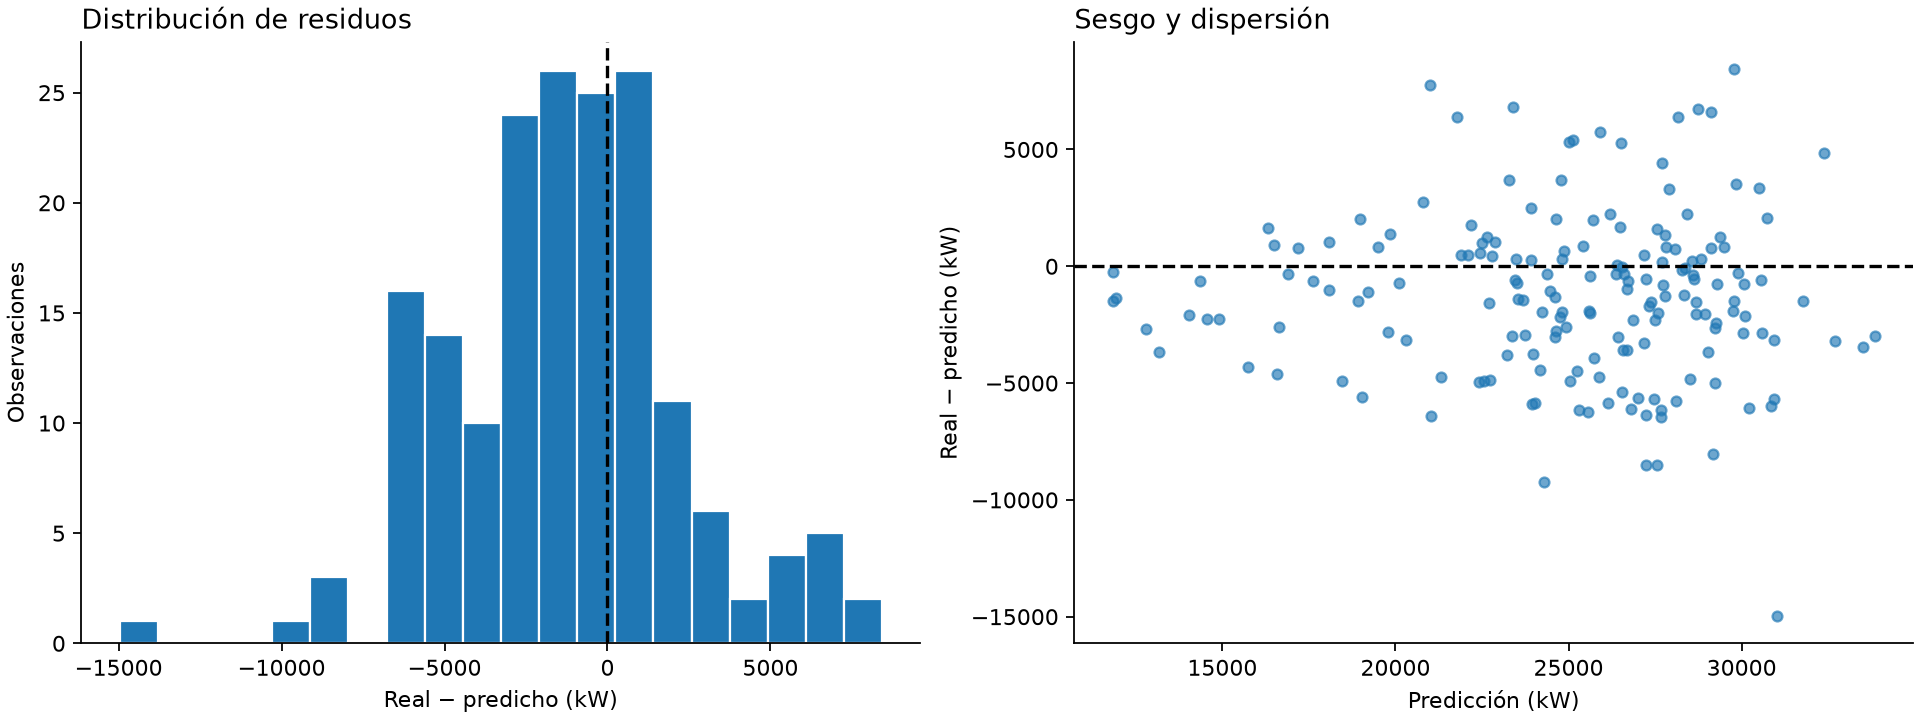

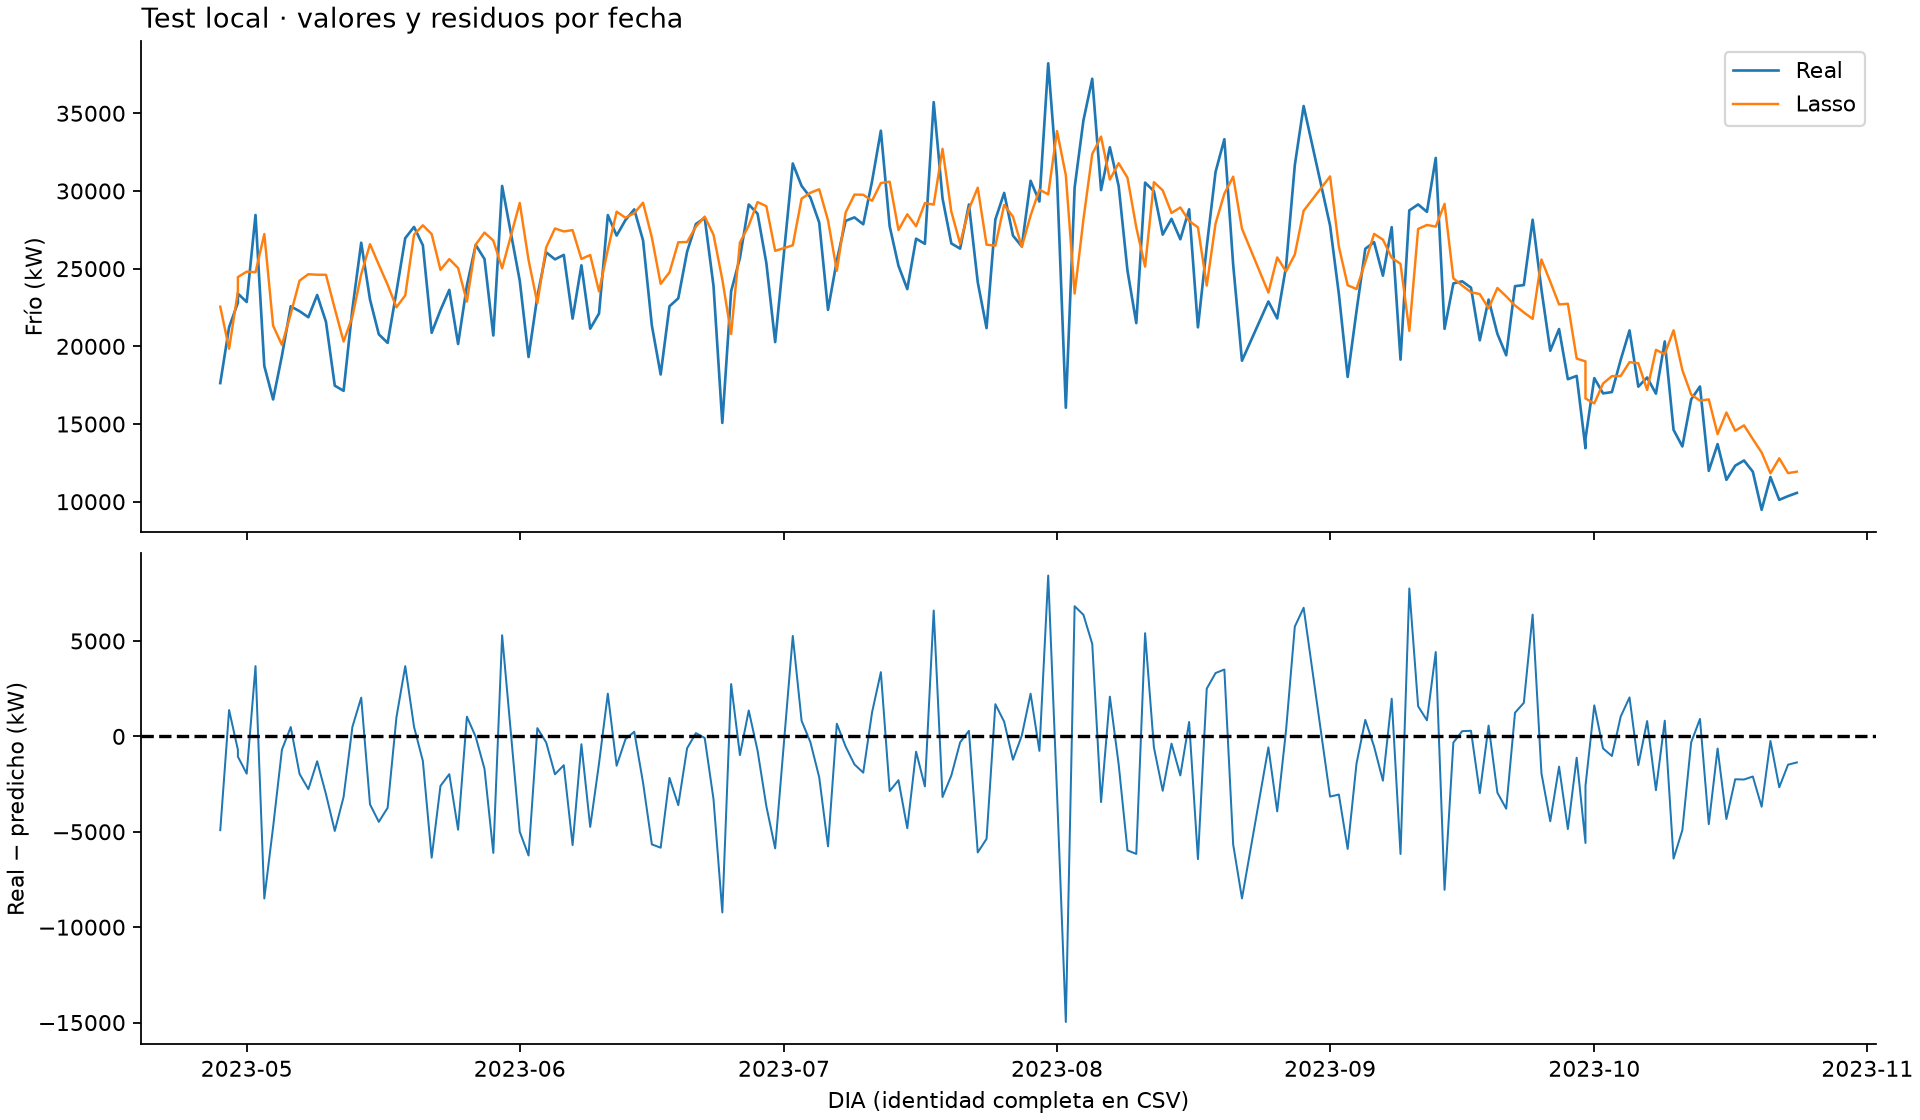

In [5]:
mostrar(10, "Resumen de residuos de test local", pd.DataFrame([leer("resumen_residuos.json")]))
mostrar(11, "Residuos por nivel de consumo real", pd.read_csv(SALIDA / "residuos_por_cuartil.csv"))
mostrar(12, "Observaciones con mayor error absoluto", pd.read_csv(SALIDA / "errores_mayores.csv"))
display(Image(filename=str(SALIDA / "diagnostico_residuos.png")))
display(Image(filename=str(SALIDA / "predicciones_y_residuos_temporales.png")))

## 6. Coeficientes e interpretación

Los coeficientes están expresados en unidades de frío por una desviación estándar del predictor imputado. El signo indica la dirección de la relación condicional. La magnitud permite una comparación descriptiva en la escala estandarizada, pero la correlación entre entradas y las interacciones redistribuyen los coeficientes. No demuestra causalidad ni una importancia estable fuera de muestra.

Tabla 13. Coeficientes de Lasso definitivo ordenados por magnitud


,variable,coeficiente_estandarizado,magnitud_absoluta,escala_train_validation
0,Frio (Kw),2824.711288,2824.711288,7697.903764
1,frio_media_7_dias,2166.681866,2166.681866,7107.191569
2,dia_anio_coseno,-1655.266217,1655.266217,0.695877
3,Totalizadores Energia | KW Trafo 9,834.595962,834.595962,5008.384651
4,Sala Maq (Kw),44.321820,44.321820,8583.132348
5,Consolidado Agua | Agua Planta (Hl),24.570932,24.570932,8205.782381
6,Servicios (Kw),0.000000,0.000000,9993.317551
7,Frio (Kw) x Consolidado Agua | Agua Planta (Hl),0.000000,0.000000,408793136.157435
8,Frio (Kw) x frio_hace_2_dias,-0.000000,0.000000,335156383.413913
9,Frio (Kw) x Totalizadores Energia | KW Trafo 9,0.000000,0.000000,196509760.646016


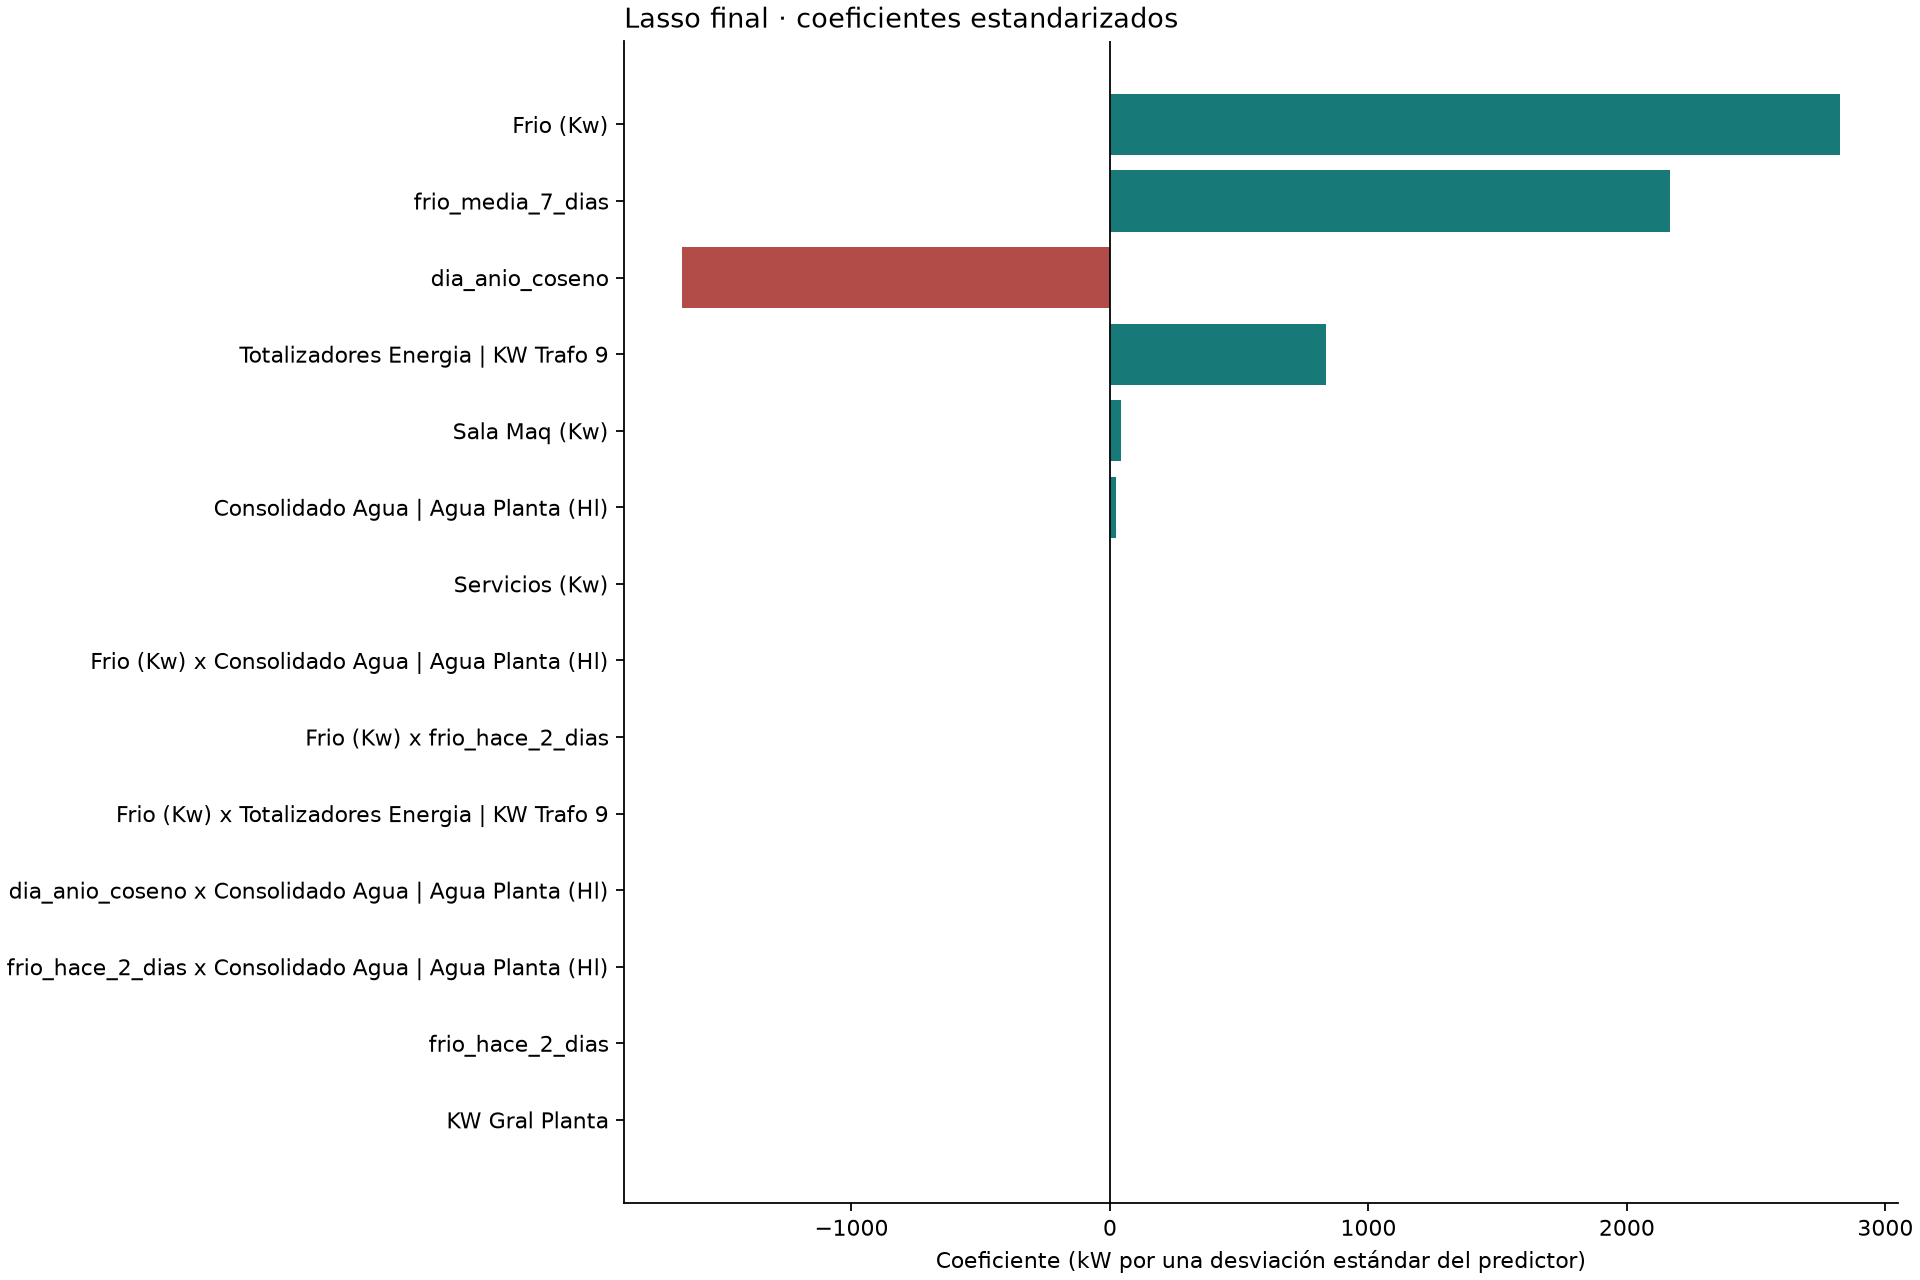

In [6]:
mostrar(13, "Coeficientes de Lasso definitivo ordenados por magnitud", pd.read_csv(SALIDA / "coeficientes.csv"))
display(Image(filename=str(SALIDA / "coeficientes.png")))

## 7. Controles de trazabilidad

Las comprobaciones enlazan registry, métricas, eventos y predicciones archivadas. No se abre el dataset ni se usa el estimador. La prueba de reproducibilidad del ajuste se realizó antes de la evaluación única y se conserva como evidencia. Los fallos históricos de auditoría y sus correcciones se explican en la documentación del cierre.

In [7]:
import hashlib
registro = json.loads((RAIZ / "models/model_registry.json").read_text(encoding="utf-8"))[meta["version"]]
predicciones = pd.read_csv(SALIDA / "predicciones_test.csv")
eventos = log.loc[log.notas.str.contains("evento=evaluacion_final_unica", na=False)]
controles = pd.Series({
    "Catorce entradas sin objetivo ni indicador adicional": len(meta["columnas"]) == 14 and "objetivo" not in meta["columnas"] and "es_fin_de_anio" not in meta["columnas"],
    "Registry conserva la validación original": registro["metricas_validacion_original"] == meta["metricas_validacion_original"],
    "Registry coincide con test": registro["metricas_test_local"] == resultado["metricas"],
    "Modelo conserva su huella": hashlib.sha256((RAIZ / meta["path"]).read_bytes()).hexdigest() == meta["modelo_sha256"],
    "Predicciones conservan su huella": hashlib.sha256((SALIDA / "predicciones_test.csv").read_bytes()).hexdigest() == resultado["predicciones_sha256"],
    "Todos los modelos comparten soporte": len(eventos) == 3 and eventos.filas.eq(len(predicciones)).all(),
    "Residuo coincide con real menos predicho": np.allclose(predicciones.residuo, predicciones.real-predicciones.predicho),
    "Identidades únicas de las filas": predicciones.indice_csv.is_unique,
    "Evaluación única archivada": resultado["evaluaciones_predict_test"] == 1 and leer("test_consumido.json")["estado"] == "completo_no_repetir",
    **meta["reproducibilidad"],
})
mostrar(14, "Controles del cierre", controles.to_frame("Cumple"), precision=0)
assert controles.all(), controles[~controles]

Tabla 14. Controles del cierre


,Cumple
Catorce entradas sin objetivo ni indicador adicional,True
Registry conserva la validación original,True
Registry coincide con test,True
Modelo conserva su huella,True
Predicciones conservan su huella,True
Todos los modelos comparten soporte,True
Residuo coincide con real menos predicho,True
Identidades únicas de las filas,True
Evaluación única archivada,True
dos_ajustes_coinciden,True


## 8. Conclusión

La validación ya intervino en la selección de variables, por lo que puede ser optimista. La etiqueta representa el bloque siguiente y no está certificada su correspondencia con fecha física ni la disponibilidad operativa a las 23:59. Se separaron índices de ajuste y prueba y se conservó la preparación histórica. La conclusión local se obtiene de los resultados sin revisar la elección del candidato. Fase 4 y test oculto quedan fuera de esta tarea.

In [8]:
mejor_baseline = min(["persistencia", "media_movil"], key=lambda b: resultado["metricas"][b]["mae"])
mejora = resultado["comparaciones"][mejor_baseline]["mejora_porcentual"]
print(f"Lasso v{meta['version']} obtuvo MAE local {resultado['metricas']['lasso']['mae']:.6f}, frente al MAE de validación histórico {meta['metricas_validacion_original']['mae']:.6f}.")
print(f"La mejora frente al mejor baseline ({mejor_baseline}) fue {mejora:.6f} % sobre {resultado['filas_evaluadas']} observaciones.")
print(f"Supera ambos baselines: {resultado['supera_ambos_baselines']}. MAE local inferior a 3000: {resultado['mae_local_menor_3000']}.")
if mejora < 10:
    print("La ganancia es menor al 10 %. No justificaría desplegar el pipeline por precisión únicamente; aporta interpretación lineal pero requiere mantener imputación, escalado y dependencias. Se conserva el candidato fijado y no se ajusta después de test.")
else:
    print("La mejora local supera el 10 % y aporta evidencia a favor del costo del pipeline, sin garantizar rendimiento futuro ni en test oculto.")
print("La evaluación local no acredita el umbral del test oculto. Los resultados completos de pruebas y trazabilidad están en verificacion_final.json.")

Lasso v1.0.0 obtuvo MAE local 2886.038956, frente al MAE de validación histórico 2215.796375.
La mejora frente al mejor baseline (media_movil) fue 5.801503 % sobre 176 observaciones.
Supera ambos baselines: True. MAE local inferior a 3000: True.
La ganancia es menor al 10 %. No justificaría desplegar el pipeline por precisión únicamente; aporta interpretación lineal pero requiere mantener imputación, escalado y dependencias. Se conserva el candidato fijado y no se ajusta después de test.
La evaluación local no acredita el umbral del test oculto. Los resultados completos de pruebas y trazabilidad están en verificacion_final.json.
